In [34]:
import numpy as np  # Import the libraries or provided helpers used below.
import matplotlib.pyplot as plt  # Import the libraries or provided helpers used below.
from typing import Callable, Iterator, List, Optional, Tuple, Union  # Import the libraries or provided helpers used below.
from bayesian_network import BayesNet  # Import the libraries or provided helpers used below.
from utils import sample_forward, get_default_bayes_net, draw_graph  # Import the libraries or provided helpers used below.


### BayesNet Class
<div class="alert alert-danger">

**Read the `BayesNet_class_description.ipynb` notebook** before you start working on this problem set! It contains a detailed description of the provided classes *BayesNet* and *Variable* that you will use to solve the following problems.
</div>


The following is a quick refresher on how to use the BayesNet class, including an introduction to visually depicting a Bayesian Network structure from a BayesNet object.

Assume we want to encode the model that factorizes in the following way:

$$ P(A, B, C) = P(A) \cdot P(B \mid A) \cdot P(C \mid A, B).$$

Variables $A, B$ and $C$ will get indices 0, 1, and 2, respectively. The corresponding list will then look like this (following the same naming conventions as used in the previous exercises):

In [35]:
_A_, _B_, _C_ = 0, 1, 2  # Assign readable names to the data column indices.
# create dummy PDTs
pdts = [  # Store the value used by the following example or experiment.
    (np.ones((2,))*0.5, (_A_,)),   # Define a probability table with the child on axis zero.
    (np.ones((2,2))*0.5, (_B_, _A_)),   # Define a probability table with the child on axis zero.
    (np.ones((2,2,2))*0.5, (_C_, _A_, _B_))  # Define a probability table with the child on axis zero.
]


Each tuple in the list corresponds to a variable, where
 - the first element in each tuple contains the (conditional) PDT, 
 - the second one describes the table's semantics (indices).

A new BayesNet can be created by passing a tuple for each variable to the constructor. Use the asterisk (\*) operator to pass an arbitrary number of tuples as arguments to the constructor:

In [36]:
bn = BayesNet(*pdts)  # Construct the network from probability tables and their variable IDs.


In [37]:
print(bn.pdts)  # Display this result for inspection.
print(bn.indices)  # Display this result for inspection.


(array([0.5, 0.5]), array([[0.5, 0.5],
       [0.5, 0.5]]), array([[[0.5, 0.5],
        [0.5, 0.5]],

       [[0.5, 0.5],
        [0.5, 0.5]]]))
((0,), (1, 0), (2, 0, 1))


Note that they are returned as tuples to make sure they should not be modified. With `list(bn.pdts)` and `list(bn.indices)` you can convert them back to lists if needed.

We are also providing a new utility function to draw the structure of a BayesNet:

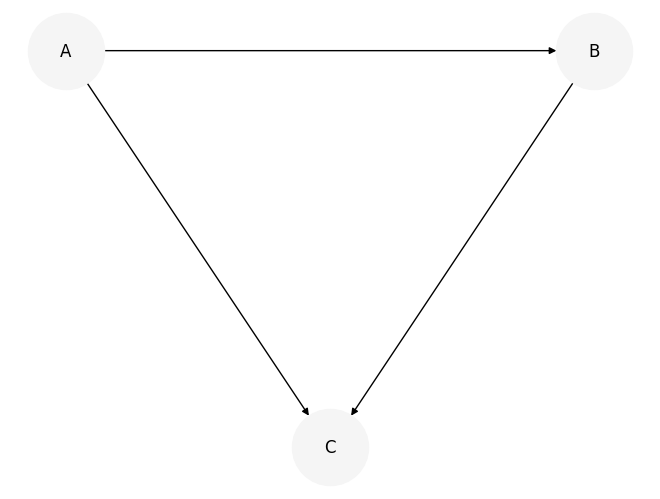

In [38]:
draw_graph(  # Visualize the dependency structure of the example network.
    bn,   # Pass the example network to the graph drawing helper.
    node_names=['A', 'B', 'C'],   # Label graph nodes with the variable names.
    pos={'A': [0., 1.], 'B': [1., 1.], 'C': [.5, .5]}  # Place graph nodes at these display coordinates.
)


In [39]:
help(draw_graph)  # Show the documentation of the graph drawing helper.


Help on function draw_graph in module utils:

draw_graph(bayes_net: bayesian_network.BayesNet, node_names: list = None, pos: dict = None) -> None
    Draws the Bayesian net.
    :param bayes_net: a BayesNet object representing the graph structure to draw.
    :param node_names: Display Name of the variables. 
                       Defaults to values for the stroke-example.
    :param pos: position of the variables (dict: key=variable_name, value: list: x, y). 
                Defaults to values for the stroke-example.



---
# Parameter Learning

In this notebook, we will assume a fixed dependency graph structure and learn the parameters (the complete Conditional Probability Distribution Table (CPDT)) from a set of events. Later, we will use log-likelihood to try to find a model structure that also generalizes to future data.
    
## 1. ML Estimates for Conditional Distributions

<div class="alert alert-warning">
    Implement the <i>maximum_likelihood_estimate</i> function, which computes the Maximum Likelihood Estimate for the parameters of a discrete (conditional) probability distribution $ P(X \mid \mathit{pa}(X) )$, given a data set.
</div>

`maximum_likelihood_estimate` takes  three parameters:
- `data` is a NumPy array of shape `(num_samples, num_variables)`.
- `variable_id` is the column index of the variable to estimate the distribution for.
- `parent_ids` is a tuple, containing the column indices of parent variables.
- `variable_cardinality` is the cardinality of the variables (aligned with columns of data)
- `alpha` is a non-negative float, corresponding to pseudocounts in Laplace smoothing.

`maximum_likelihood_estimate` must return one object:
- A Maximum Likelihood Estimate (MLE) of the parameters in form of a `np.ndarray`. The first dimension (index `0`) of the returned array must correspond to variable `variable_id`, the remaining dimensions must be sorted according to `parent_ids`. Altogether, tuple `(variable_id, ) + parent_ids` gives the mapping of dimensions to variables.

Hint:
- To count elements in a Numpy array, you can simply loop over the data array.
- The smoothing parameter `alpha` is added to the counts of each possible event represented in the CPDT.

In [40]:
def maximum_likelihood_estimate(data: np.ndarray, variable_id: int, parent_ids: tuple=tuple(), variable_cardinality: Union[Tuple[int], None]=tuple(), alpha: float=0):  # Estimate one discrete conditional probability table.
    """Count observed events, add alpha per outcome, and normalize over the child.

    Axes follow (variable_id,) + parent_ids, preserving the supplied parent order.
    With alpha=0, an unseen parent configuration has no unique MLE; use a
    uniform distribution for that column as an explicit convention.
    """
    assert isinstance(parent_ids, tuple)  # Require an ordered tuple of parent column IDs.
    assert variable_cardinality is None or isinstance(variable_cardinality, tuple)  # Accept explicit cardinalities or the binary default.
    assert np.isfinite(alpha) and alpha >= 0  # Pseudocounts must be finite and nonnegative.

    if variable_cardinality is None or len(variable_cardinality) == 0:  # Detect an omitted cardinality specification.
        variable_cardinality = (2,) * data.shape[1]  # Assume two outcomes per variable by default.


    # Put the child first and retain the requested parent order
    variable_ids = (variable_id,) + parent_ids 

    # Determine the number of outcomes along each table axis
    shape = tuple(variable_cardinality[i] for i in variable_ids) 

    # Initialize every possible event with its smoothing pseudocount 
    counts = np.full(shape, alpha, dtype=float)  

    # Visit each observed joint event once
    for sample in data:  

        # Select the child value and the corresponding parent values
        index = tuple(sample[i] for i in variable_ids) 

        # Add one observation to that exact table entry
        counts[index] += 1  

    # Sum over child values separately for each parent configuration
    totals = counts.sum(axis=0, keepdims=True)  

    # Prepare a uniform fallback for configurations with zero total count
    cpdt = np.full(shape, 1.0 / shape[0], dtype=float) 

    # Normalize observed or smoothed columns without dividing by zero
    np.divide(counts, totals, out=cpdt, where=totals > 0)  
    return cpdt 


In [41]:
import traceback  # Import the libraries or provided helpers used below.

any_failed = False  # Track whether any supplied sanity check failed.

try:  # Run the supplied sanity checks and report any failure.
    # sanity checks
    _A_, _B_, _C_, _D_, _E_ = 0, 1, 2, 3, 4  # Assign readable names to the data column indices.
    # get the bayes net from the previous problem
    bayes_net = get_default_bayes_net()  # Store the value used by the following example or experiment.
    np.random.seed(0)  # Fix the random seed so the experiment is reproducible.
    # draw 100 samples
    data = sample_forward(bayes_net, 100)  # Generate independent observations from the specified network.
    
    # get exact A form bayes net
    expected = bayes_net[_A_].pdt[:,0,0,0,0]  # Set the reference value for this sanity check.
    # estimate A from the data
    actual = maximum_likelihood_estimate(data, _A_)  # Estimate this variable distribution from training counts using the listed parents.
    # estimate should not be far off
    assert np.all(np.isclose(expected, actual, atol=0.05))  # Verify the expected numerical result or normalization.
    
    # get exact B_A form bayes net
    expected = bayes_net[_B_].pdt[:,:,0,0,0].T  # Set the reference value for this sanity check.
    # estimate B_A from data
    actual = maximum_likelihood_estimate(data, _B_, (_A_,))  # Estimate this variable distribution from training counts using the listed parents.
    # estimate should not be far off
    assert np.all(np.isclose(expected, actual, atol=0.05))  # Verify the expected numerical result or normalization.
    
    # test if alpha correctly added
    expected = [0.29166667, 0.70833333]  # Set the reference value for this sanity check.
    # estimate A from the data with alpha=10
    actual = maximum_likelihood_estimate(data, _A_, alpha=10)  # Estimate this variable distribution from training counts using the listed parents.
    # estimate should not be far off
    assert np.all(np.isclose(expected, actual, atol=0.05))  # Verify the expected numerical result or normalization.
    
except Exception as e:  # Catch and report an error in the sanity checks.
    print("Error:", e)  # Display this result for inspection.
    traceback.print_exception(type(e), e, e.__traceback__)  # Display the traceback to locate a failed check.
    any_failed = True  # Track whether any supplied sanity check failed.
    
assert not any_failed, "See error message above..."  # Verify the expected numerical result or normalization.


### 2. The Log-Likelihood Function

<div class="alert alert-warning">
    Implement the <i>log_likelihood</i> function, which computes the log-likelihood $\mathcal{L}(\mathcal{M} : \mathcal{D})$ of a model (BayesNet) relative to a data set.
</div>

`log_likelihood` takes two parameters:
- `data` is a NumPy array of shape `(num_samples, num_variables)`.
- `bayes_net` a BayesNet object representing the model $\mathcal{M}$ (containing already estimated CPDTs).

`log_likelihood` must return one object:
- The log-likelihood of the model given the data (i.e., a floating point number (<= 0)).

Hint:
- Recall that iterating over the variables in the BayesNet is easy: `for variable in bayes_net: ...`.
- The probability distribution of variable $X$ given its parents $\mathit{pa}(X)$, $P(X \mid \mathit{pa}(X))$, can be obtained by passing the random event to the variable, i.e., `variable(data[i])`.
- Use the natural logarithm for your computations, i.e. `np.log`.

In [42]:
def log_likelihood(data: np.ndarray, bayes_net: BayesNet):  # Score the entire data set under a fixed Bayesian network.
    """Return sum_n sum_i log P(x_i^(n) | pa(x_i)^(n)), using natural logs."""
    ll = 0.0  # Start with the log of an empty product, which is zero.

    # Process every observed joint event
    for sample in data:  

        # Visit every factor of the Bayesian network
        for variable in bayes_net:  
            # Select the probability of the observed child value given its parents
            probability = variable(sample)[sample[variable.id]] 

            # Detect an event that the model considers impossible 
            if probability == 0:  
                # A zero probability makes the complete data likelihood zero and its log minus infinity
                return float('-inf')  

             # Add this factor's natural logarithm instead of multiplying small probabilities
            ll += np.log(probability) 
    return float(ll)


In [43]:
any_failed = False  # Track whether any supplied sanity check failed.
try:  # Run the supplied sanity checks and report any failure.
    # sanity checks
    # get the bayes net from the previous problem
    bayes_net = get_default_bayes_net()  # Store the value used by the following example or experiment.
    np.random.seed(0)  # Fix the random seed so the experiment is reproducible.
    # draw 100 samples
    data = sample_forward(bayes_net, 100)  # Generate independent observations from the specified network.
    
    # expected log-likelihood
    expected = -215.9  # Set the reference value for this sanity check.
    # actual log-likelihood
    actual = log_likelihood(data, bayes_net)  # Compute the total log-likelihood of these data under this model.
    # must be close
    assert np.all(np.isclose(expected, actual, atol=10.0))  # Verify the expected numerical result or normalization.
except Exception as e:  # Catch and report an error in the sanity checks.
    print("Error:", e)  # Display this result for inspection.
    traceback.print_exception(type(e), e, e.__traceback__)  # Display the traceback to locate a failed check.
    any_failed = True  # Track whether any supplied sanity check failed.

assert not any_failed, "See error message above..."  # Verify the expected numerical result or normalization.


## Finding a Model for Strokes   

After watching hours of medical dramas on television, you try to figure out the perfect prediction model for strokes. Some of your AI colleagues told you about how Bayesian networks can be used for symptom diagnosis, so you decide to model your ideas using this technique. 

Let's assume that you magically know the true underlying Bayes model (structure and parameters); all variables in this example are boolean (false=0 or true=1).  

<img  style='width:100%;  max-width:400px;' src="img/bn_mod2.svg">

The conditional probability tables are given as follows:

<table style="float: left;margin:5px;"><tr><th>P(A)</th><th>$a_0$<br></th><th>$a_1$</th></tr><tr><td>-</td><td>0.01</td><td>0.99</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(H | A)</th><th>$a_0$<br></th><th>$a_1$</th></tr><tr><td>$h_0$</td><td>0.9</td><td>0.8</td></tr><tr><td>$h_1$</td><td>0.1</td><td>0.2</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(S | H)</th><th>$h_0$<br></th><th>$h_1$</th></tr><tr><td>$s_0$</td><td>0.9</td><td>0.85</td></tr><tr><td>$s_1$</td><td>0.1</td><td>0.15</td></tr></table>


<table style="float: left;margin:5px;"><tr><th rowspan="2">P(C | A, S)</th><th colspan="2">$a_0$<br></th><th colspan="2">$a_1$</th></tr><tr><td>$s_0$</td><td>$s_1$</td><td>$s_0$</td><td>$s_1$</td></tr><tr><td>$c_0$<br></td><td>0.8</td><td>0.7</td><td>0.85</td><td>0.45</td></tr><tr><td>$c_1$</td><td>0.2</td><td>0.3</td><td>0.15</td><td>0.55</td></tr></table>

<table style="float: left;margin:5px;"><tr><th>P(V | S)</th><th>$s_0$</th><th>$s_1$</th></tr><tr><td>$v_0$</td><td>0.1</td><td>0.2</td></tr><tr><td>$v_1$</td><td>0.9</td><td>0.8</td></tr></table>  

In order to find a good model, you would need to collect a lot of training examples. But since we know the true underlying model, you can instead just sample 5000 events from this network as the training data, and 5000 samples as the test data.

In [44]:
_A_, _H_, _S_, _C_, _V_ = 0, 1, 2, 3, 4  # Assign readable names to the data column indices.
A = np.array([0.01, 0.99])  # Define a probability table with the child on axis zero.
H_A = np.array([[0.9, 0.8], [0.1, 0.2]])  # Define a probability table with the child on axis zero.
S_H = np.array([[0.9, 0.85], [0.1, 0.15]])  # Define a probability table with the child on axis zero.
C_AS = np.array([[[0.8, 0.7], [0.85, 0.45]], [[0.2, 0.3], [0.15, 0.55]]])  # Define a probability table with the child on axis zero.
V_S = np.array([[0.1, 0.2], [0.9, 0.8]])  # Define a probability table with the child on axis zero.

# this bayes net represents the true underlying full joint distribution in the medical world 
true_bayes_net = BayesNet(  # Construct the network from probability tables and their variable IDs.
    (A, (_A_,)),  # Associate the table axes with the child ID followed by its parent IDs.
    (H_A, (_H_,_A_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (S_H, (_S_,_H_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (C_AS, (_C_,_A_,_S_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (V_S, (_V_,_S_))  # Associate the table axes with the child ID followed by its parent IDs.
)
np.random.seed(0)  # Fix the random seed so the experiment is reproducible.
train = sample_forward(true_bayes_net, 5000)  # Generate independent observations from the specified network.
test = sample_forward(true_bayes_net, 5000)  # Generate independent observations from the specified network.


### Experiments

Based on the sampled training data points, we now estimate the (conditional) probability tables for the true underlying network structure and compute its log-likelihood w.r.t the training data.

We store the CPDTs into the provided variables. The dimensions of the CPDT are sorted according to the naming of the variable, e.g., in C_AS, dimension 0 corresponds to C, dimension 1 to A, and dimension 2 to S.

In [45]:
_A_, _H_, _S_, _C_, _V_ = 0, 1, 2, 3, 4  # Assign readable names to the data column indices.

A, H_A, S_H, C_AS, V_S = None, None, None, None, None  # Store the value used by the following example or experiment.

A = maximum_likelihood_estimate(train, _A_)  # Estimate this variable distribution from training counts using the listed parents.
H_A = maximum_likelihood_estimate(train, _H_, (_A_,))  # Estimate this variable distribution from training counts using the listed parents.
S_H = maximum_likelihood_estimate(train, _S_, (_H_,))  # Estimate this variable distribution from training counts using the listed parents.
C_AS = maximum_likelihood_estimate(train, _C_, (_A_, _S_))  # Estimate this variable distribution from training counts using the listed parents.
V_S = maximum_likelihood_estimate(train, _V_, (_S_,))  # Estimate this variable distribution from training counts using the listed parents.

# begin sanity check
assert np.all(np.isclose(A.sum(axis=0), 1))  # Verify the expected numerical result or normalization.
assert np.all(np.isclose(H_A.sum(axis=0), 1))  # Verify the expected numerical result or normalization.
assert np.all(np.isclose(S_H.sum(axis=0), 1))  # Verify the expected numerical result or normalization.
assert np.all(np.isclose(C_AS.sum(axis=0), 1))  # Verify the expected numerical result or normalization.
assert np.all(np.isclose(V_S.sum(axis=0), 1))  # Verify the expected numerical result or normalization.
# end sanity check

bayes_net_1 = BayesNet(  # Construct the network from probability tables and their variable IDs.
    (A, (_A_,)),  # Associate the table axes with the child ID followed by its parent IDs.
    (H_A, (_H_,_A_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (S_H, (_S_,_H_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (C_AS, (_C_,_A_,_S_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (V_S, (_V_,_S_))  # Associate the table axes with the child ID followed by its parent IDs.
)

tr_log_likelihood_1 = log_likelihood(train, bayes_net_1)  # Compute the total log-likelihood of these data under this model.


Back to our strokes model: Having no idea of the true underlying network structure, you decide to try out the following very simple model first:

<img  style='width:100%;  max-width:400px;' src="img/bn_mod1.svg">

Based on the sampled training data points, we estimate the (conditional) probability tables for this model and compute its log-likelihood w.r.t the training data.

In [46]:
_A_, _H_, _S_, _C_, _V_ = 0, 1, 2, 3, 4  # Assign readable names to the data column indices.

A, H, S, C, V = None, None, None, None, None  # Store the value used by the following example or experiment.

A = maximum_likelihood_estimate(train, _A_)  # Estimate this variable distribution from training counts using the listed parents.
H = maximum_likelihood_estimate(train, _H_)  # Estimate this variable distribution from training counts using the listed parents.
S = maximum_likelihood_estimate(train, _S_)  # Estimate this variable distribution from training counts using the listed parents.
C = maximum_likelihood_estimate(train, _C_)  # Estimate this variable distribution from training counts using the listed parents.
V = maximum_likelihood_estimate(train, _V_)  # Estimate this variable distribution from training counts using the listed parents.

bayes_net_2 = BayesNet(  # Construct the network from probability tables and their variable IDs.
    (A, (_A_,)),  # Associate the table axes with the child ID followed by its parent IDs.
    (H, (_H_,)),  # Associate the table axes with the child ID followed by its parent IDs.
    (S, (_S_,)),  # Associate the table axes with the child ID followed by its parent IDs.
    (C, (_C_,)),  # Associate the table axes with the child ID followed by its parent IDs.
    (V, (_V_,))  # Associate the table axes with the child ID followed by its parent IDs.
)

tr_log_likelihood_2 = 0  # Store the value used by the following example or experiment.

tr_log_likelihood_2 = log_likelihood(train, bayes_net_2)  # Compute the total log-likelihood of these data under this model.


Unhappy with the result, you decide to try out a second, more complex model:

<img  style='width:100%;  max-width:400px;' src="img/bn_mod3.svg">

Based on the sampled training data points, we estimate the (conditional) probability tables for this model and compute its log-likelihood w.r.t the training data.

In [47]:
_A_, _H_, _S_, _C_, _V_ = 0, 1, 2, 3, 4  # Assign readable names to the data column indices.

A, H_A, S_AH, C_AS, V_CS = None, None, None, None, None  # Store the value used by the following example or experiment.

A = maximum_likelihood_estimate(train, _A_)  # Estimate this variable distribution from training counts using the listed parents.
H_A = maximum_likelihood_estimate(train, _H_, (_A_,))  # Estimate this variable distribution from training counts using the listed parents.
S_AH = maximum_likelihood_estimate(train, _S_, (_A_, _H_,))  # Estimate this variable distribution from training counts using the listed parents.
C_AS = maximum_likelihood_estimate(train, _C_, (_A_, _S_))  # Estimate this variable distribution from training counts using the listed parents.
V_CS = maximum_likelihood_estimate(train, _V_, (_C_,_S_,))  # Estimate this variable distribution from training counts using the listed parents.

bayes_net_3 = BayesNet(  # Construct the network from probability tables and their variable IDs.
    (A, (_A_,)),  # Associate the table axes with the child ID followed by its parent IDs.
    (H_A, (_H_,_A_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (S_AH, (_S_,_A_,_H_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (C_AS, (_C_,_A_,_S_)),  # Associate the table axes with the child ID followed by its parent IDs.
    (V_CS, (_V_,_C_,_S_))  # Associate the table axes with the child ID followed by its parent IDs.
)

tr_log_likelihood_3 = 0  # Store the value used by the following example or experiment.

tr_log_likelihood_3 = log_likelihood(train, bayes_net_3)  # Compute the total log-likelihood of these data under this model.


### Compare Train Log-Likelihoods

Compare the log-likelihoods w.r.t the training data of Model **M1** (having the true underlying structure) to the two new models (**M2** - no edges, **M3** - complex model).

In [48]:
print('logP(train|M1) = {}'.format(tr_log_likelihood_1))  # Display this result for inspection.
print('logP(train|M2) = {}'.format(tr_log_likelihood_2))  # Display this result for inspection.
print('logP(train|M3) = {}'.format(tr_log_likelihood_3))  # Display this result for inspection.


logP(train|M1) = -8508.579282438383
logP(train|M2) = -8740.033479010004
logP(train|M3) = -8504.427454360399


### Compare Test Log-Likelihoods

Finally, we compute the test log-likelihood of the model **M1** (having the true underlying structure) and the newly created models **M2** and **M3**.

In [49]:
te_log_likelihood_1 = log_likelihood(test, bayes_net_1)  # Compute the total log-likelihood of these data under this model.
te_log_likelihood_2 = log_likelihood(test, bayes_net_2)  # Compute the total log-likelihood of these data under this model.
te_log_likelihood_3 = log_likelihood(test, bayes_net_3)  # Compute the total log-likelihood of these data under this model.

print('logP(test|M1) = {}'.format(te_log_likelihood_1))  # Display this result for inspection.
print('logP(test|M2) = {}'.format(te_log_likelihood_2))  # Display this result for inspection.
print('logP(test|M3) = {}'.format(te_log_likelihood_3))  # Display this result for inspection.


logP(test|M1) = -8376.49246068484
logP(test|M2) = -8598.449646741903
logP(test|M3) = -8379.468463963516


### Implementation notes
The estimator supports arbitrary discrete cardinalities, preserves the supplied parent order, and uses additive smoothing: `(count + alpha) / (parent_count + child_cardinality * alpha)`. For an unseen parent configuration at alpha=0, any normalized column maximizes the likelihood; this implementation chooses a uniform column.
The score is the **sum**, not the mean, of natural log probabilities over all observations and all network factors. An impossible observation returns `-inf`; an empty data set returns `0.0`. M3 contains the M1 structure plus extra edges, so its maximized training likelihood cannot be lower, but its test likelihood can be worse because of overfitting.
